In [13]:
import numpy as np, pandas as pd, gurobipy as gp
from gurobipy import GRB
from collections import defaultdict
from pathlib import Path

ROOT = Path("..")      # the data files sit one folder above Notebooks/

L = np.load(ROOT / "L_metres.npy"); site_dist = np.load(ROOT / "site_dist.npy")       # from notebook 03

sites = pd.read_csv(ROOT / "sites.csv")
d = pd.read_csv(ROOT / "demand_d_it.csv", index_col=0); d.columns = [int(c) for c in d.columns]

DV0 = d.values
nJ, nI = L.shape
J, I, T = range(nJ), range(nI), range(4)

CAP = {"S": 1, "M": 3, "L": 5}
FIX = {"EMS": {"S": 0.0, "M": 1.0, "L": 2.0}, "OTHER": {"S": 1.5, "M": 2.5, "L": 3.5}}

F = {(j, k): FIX["EMS" if sites.loc[j, "site_type"] == "EMS" else "OTHER"][k] for j in J for k in CAP}

is_ems = (sites["site_type"] == "EMS").values
is_fire = (sites["site_type"] == "FIREHOUSE").values
H = 6
R = pd.read_csv(ROOT / "kappa_t.csv", index_col=0)["R"].values       # from notebook 01

def make_a(theta=8, speed=15, beta=0.15):
    kappa = 1 + beta * np.clip(R - 1, 0, None)
    miles = (L + site_dist[:, None]) / 1609.344
    tau = kappa[None, None, :] * miles[:, :, None] / speed * 60
    return tau <= theta

def reach(a, dv):                                   # share of demand that at least one site can reach
    return sum(dv[a[:, :, t].any(axis=0), t].sum() for t in T) / dv.sum()

def solve(a, dv, B=30.0, P=None, rho=0.60, s=1.5, c=0.590, target=None, time_limit=30, gap=0.001):
    pairs = [(i, j, t) for j in J for i in I for t in T if a[j, i, t] and dv[i, t] > 0]
    by_it, by_jt = defaultdict(list), defaultdict(list)
    for i, j, t in pairs:
        by_it[(i, t)].append(j); by_jt[(j, t)].append(i)
    m = gp.Model(); m.setParam("OutputFlag", 0); m.setParam("TimeLimit", time_limit); m.setParam("MIPGap", gap)
    q = m.addVars(J, list(CAP), vtype=GRB.BINARY); n = m.addVars(J, vtype=GRB.INTEGER, lb=0)
    f = m.addVars(pairs, lb=0.0)
    cost = gp.quicksum(F[j, k] * q[j, k] for j in J for k in CAP) + c * n.sum()
    m.addConstrs((q.sum(j, "*") <= 1 for j in J))
    m.addConstrs((n[j] >= q.sum(j, "*") for j in J))
    m.addConstrs((n[j] <= gp.quicksum(CAP[k] * q[j, k] for k in CAP) for j in J))
    for (i, t), js in by_it.items():
        m.addConstr(gp.quicksum(f[i, j, t] for j in js) <= dv[i, t])
    for (j, t), is_ in by_jt.items():
        m.addConstr(s * gp.quicksum(f[i, j, t] for i in is_) <= rho * H * n[j])
    if P is not None:
        m.addConstr(n.sum() <= P)
    if target is None:                                  # mode 1: best coverage within budget B
        m.addConstr(cost <= B); m.setObjective(f.sum(), GRB.MAXIMIZE)
    else:                                               # mode 2: cheapest plan reaching target coverage
        m.addConstr(f.sum() >= target * dv.sum()); m.setObjective(cost, GRB.MINIMIZE)
    m.optimize()
    if m.SolCount == 0:
        return dict(coverage=np.nan, cost=np.nan, ambulances=np.nan)
    return dict(coverage=sum(v.X for v in f.values()) / dv.sum(), cost=cost.getValue(),
                ambulances=int(round(n.sum().getValue())))

def metrics(a, dv, **kw):
    r1 = solve(a, dv, B=10, **kw)
    r2 = solve(a, dv, target=0.95, **kw)
    return dict(max_reach=round(reach(a, dv), 4), cov_at_10m=round(r1["coverage"], 4),
                cost_for_95=round(r2["cost"], 2), ambulances_for_95=r2["ambulances"])

base = metrics(make_a(), DV0)
print(base)

{'max_reach': np.float64(0.9994), 'cov_at_10m': np.float64(0.9949), 'cost_for_95': 6.81, 'ambulances_for_95': 9}


In [14]:
rows = []
for theta in [6, 7, 8, 9, 10, 12]:
    rows.append(dict(theta_min=theta, **metrics(make_a(theta=theta), DV0)))
pd.DataFrame(rows)

,theta_min,max_reach,cov_at_10m,cost_for_95,ambulances_for_95
0,6,0.9975,0.8710,13.67,13
1,7,0.9994,0.9645,8.90,10
2,8,0.9994,0.9949,6.81,9
3,9,0.9994,0.9991,5.04,6
4,10,0.9994,0.9991,4.45,5
5,12,1.0000,0.9994,2.36,4


In [15]:
def build(a, dv, rho=0.60, s=1.5, c=0.590):
    pairs = [(i, j, t) for j in J for i in I for t in T if a[j, i, t] and dv[i, t] > 0]
    by_it, by_jt = defaultdict(list), defaultdict(list)
    for i, j, t in pairs:
        by_it[(i, t)].append(j); by_jt[(j, t)].append(i)
    m = gp.Model(); m.setParam("OutputFlag", 0)
    q = m.addVars(J, list(CAP), vtype=GRB.BINARY); n = m.addVars(J, vtype=GRB.INTEGER, lb=0)
    f = m.addVars(pairs, lb=0.0)
    cost = gp.quicksum(F[j, k] * q[j, k] for j in J for k in CAP) + c * n.sum()
    m.addConstrs((q.sum(j, "*") <= 1 for j in J))
    m.addConstrs((n[j] >= q.sum(j, "*") for j in J))
    m.addConstrs((n[j] <= gp.quicksum(CAP[k] * q[j, k] for k in CAP) for j in J))
    for (i, t), js in by_it.items():
        m.addConstr(gp.quicksum(f[i, j, t] for j in js) <= dv[i, t])
    for (j, t), is_ in by_jt.items():
        m.addConstr(s * gp.quicksum(f[i, j, t] for i in is_) <= rho * H * n[j])
    opened = {j: q.sum(j, "*") for j in J}
    for (i, j, t) in pairs:
        m.addConstr(f[i, j, t] <= dv[i, t] * opened[j])
    bud = m.addConstr(cost <= 30.0)
    m.setObjective(f.sum(), GRB.MAXIMIZE)
    return m, bud, dv.sum()

def cov_at(m, bud, total, B, time_limit=20, gap=0.001):
    bud.RHS = B
    m.setParam("TimeLimit", time_limit); m.setParam("MIPGap", gap)
    m.optimize()
    cov = m.ObjVal / total if m.SolCount else 0.0
    return cov, (m.Status == GRB.OPTIMAL)

In [16]:
import time
a0 = make_a()
m, bud, total = build(a0, DV0)
for B in (6, 10):
    t0 = time.time()
    cov, ok = cov_at(m, bud, total, B, time_limit=30, gap=0.001)
    print(f"B={B}: coverage {cov:.4f}, proven optimal: {ok}, seconds: {time.time()-t0:.1f}", flush=True)

B=6: coverage 0.9262, proven optimal: True, seconds: 1.0
B=10: coverage 0.9949, proven optimal: True, seconds: 1.1


In [17]:
import time

def scenario(a, dv, target=0.95):
    m, bud, total = build(a, dv)
    non_opt = 0
    cov10, ok = cov_at(m, bud, total, 10, time_limit=60); non_opt += (not ok)
    cov30, ok = cov_at(m, bud, total, 30, time_limit=60); non_opt += (not ok)
    if cov30 < target:
        need = np.nan
    else:
        lo, hi = 0.0, 30.0
        while hi - lo > 0.05:
            mid = (lo + hi) / 2
            cv, ok = cov_at(m, bud, total, mid, time_limit=60); non_opt += (not ok)
            if cv >= target: hi = mid
            else: lo = mid
        need = hi
    return dict(cov_at_10m=round(cov10, 4), budget_for_95=round(need, 2), non_optimal=non_opt)

def grow_uniform(dv, g):
    return dv * (1 + g)

def grow_random(dv, g, seed):
    w = np.random.default_rng(seed).dirichlet(np.ones(dv.shape[0]))
    profile = dv / dv.sum(axis=1, keepdims=True)
    return dv + (g * dv.sum() * w)[:, None] * profile

a0 = make_a()
N_SEEDS = 5
rows = []
t_start = time.time()
for g in [0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    t0 = time.time()
    u = scenario(a0, grow_uniform(DV0, g))
    rnd = [scenario(a0, grow_random(DV0, g, seed)) for seed in range(N_SEEDS)]
    rows.append(dict(growth=g,
        uniform_cov_10m=u["cov_at_10m"], uniform_budget_95=u["budget_for_95"],
        random_cov_10m_mean=np.mean([r["cov_at_10m"] for r in rnd]).round(4),
        random_cov_10m_min=np.min([r["cov_at_10m"] for r in rnd]).round(4),
        random_budget_95_mean=np.mean([r["budget_for_95"] for r in rnd]).round(2),
        random_budget_95_max=np.max([r["budget_for_95"] for r in rnd]).round(2),
        non_optimal_solves=u["non_optimal"] + sum(r["non_optimal"] for r in rnd)))
    print(f"done growth {g:.2f} ({time.time() - t0:.0f}s)", flush=True)
print("total minutes:", round((time.time() - t_start) / 60, 1))
pd.DataFrame(rows)

done growth 0.00 (70s)
done growth 0.05 (72s)
done growth 0.10 (67s)
done growth 0.15 (70s)
done growth 0.20 (68s)
done growth 0.25 (70s)
done growth 0.30 (69s)
total minutes: 8.1


,growth,uniform_cov_10m,uniform_budget_95,random_cov_10m_mean,random_cov_10m_min,random_budget_95_mean,random_budget_95_max,non_optimal_solves
0,0.00,0.9949,6.83,0.9949,0.9949,6.83,6.83,0
1,0.05,0.9949,6.83,0.9940,0.9934,6.83,6.83,0
2,0.10,0.9949,6.83,0.9935,0.9926,6.83,6.83,0
3,0.15,0.9949,6.83,0.9932,0.9919,6.83,6.83,0
4,0.20,0.9949,6.83,0.9929,0.9913,6.83,6.83,0
5,0.25,0.9949,6.83,0.9926,0.9907,6.83,6.83,0
6,0.30,0.9943,6.83,0.9924,0.9901,6.83,6.83,0


In [18]:
def build(a, dv, rho=0.60, s=1.5, c=0.590, P=None):
    pairs = [(i, j, t) for j in J for i in I for t in T if a[j, i, t] and dv[i, t] > 0]
    by_it, by_jt = defaultdict(list), defaultdict(list)
    for i, j, t in pairs:
        by_it[(i, t)].append(j); by_jt[(j, t)].append(i)
    m = gp.Model(); m.setParam("OutputFlag", 0)
    q = m.addVars(J, list(CAP), vtype=GRB.BINARY); n = m.addVars(J, vtype=GRB.INTEGER, lb=0)
    f = m.addVars(pairs, lb=0.0)
    cost = gp.quicksum(F[j, k] * q[j, k] for j in J for k in CAP) + c * n.sum()
    m.addConstrs((q.sum(j, "*") <= 1 for j in J))
    m.addConstrs((n[j] >= q.sum(j, "*") for j in J))
    m.addConstrs((n[j] <= gp.quicksum(CAP[k] * q[j, k] for k in CAP) for j in J))
    for (i, t), js in by_it.items():
        m.addConstr(gp.quicksum(f[i, j, t] for j in js) <= dv[i, t])
    for (j, t), is_ in by_jt.items():
        m.addConstr(s * gp.quicksum(f[i, j, t] for i in is_) <= rho * H * n[j])
    opened = {j: q.sum(j, "*") for j in J}
    for (i, j, t) in pairs:
        m.addConstr(f[i, j, t] <= dv[i, t] * opened[j])
    if P is not None:
        m.addConstr(n.sum() <= P)
    bud = m.addConstr(cost <= 30.0)
    m.setObjective(f.sum(), GRB.MAXIMIZE)
    return m, bud, dv.sum()


def scenario(a, dv, target=0.95, **kw):
    m, bud, total = build(a, dv, **kw)
    non_opt = 0
    cov10, ok = cov_at(m, bud, total, 10, time_limit=60); non_opt += (not ok)
    cov30, ok = cov_at(m, bud, total, 30, time_limit=60); non_opt += (not ok)
    if cov30 < target:
        need = np.nan
    else:
        lo, hi = 0.0, 30.0
        while hi - lo > 0.05:
            mid = (lo + hi) / 2
            cv, ok = cov_at(m, bud, total, mid, time_limit=60); non_opt += (not ok)
            if cv >= target: hi = mid
            else: lo = mid
        need = hi
    return dict(cov_at_10m=round(cov10, 4), budget_for_95=round(need, 2), non_optimal=non_opt)


def metrics(a, dv, **kw):
    r = scenario(a, dv, **kw)
    return dict(max_reach=round(reach(a, dv), 4), **r)

In [19]:
rows = []
for v in [10, 12, 15, 20, 25]:
    rows.append(dict(param="speed (mph)", value=v, **metrics(make_a(speed=v), DV0)))
for b in [0.0, 0.15, 0.30, 0.50]:
    rows.append(dict(param="beta (congestion)", value=b, **metrics(make_a(beta=b), DV0)))
for r in [0.4, 0.5, 0.6, 0.7, 0.8]:
    rows.append(dict(param="rho (max utilization)", value=r, **metrics(a0, DV0, rho=r)))
for sv in [1.0, 1.5, 2.0, 2.5]:
    rows.append(dict(param="service time s (h)", value=sv, **metrics(a0, DV0, s=sv)))
for cv in [0.44, 0.59, 0.74]:
    rows.append(dict(param="cost per ambulance c ($m)", value=cv, **metrics(a0, DV0, c=cv)))
for P in [4, 6, 8, 10, 16]:
    rows.append(dict(param="fleet cap P", value=P, **metrics(a0, DV0, P=P)))
pd.DataFrame(rows)

,param,value,max_reach,cov_at_10m,budget_for_95,non_optimal
0,speed (mph),10.00,0.9953,0.7870,18.78,0
1,speed (mph),12.00,0.9981,0.9124,11.60,0
2,speed (mph),15.00,0.9994,0.9949,6.83,0
3,speed (mph),20.00,1.0000,1.0000,4.13,0
4,speed (mph),25.00,1.0000,1.0000,2.37,0
5,beta (congestion),0.00,0.9994,0.9987,4.45,0
6,beta (congestion),0.15,0.9994,0.9949,6.83,0
7,beta (congestion),0.30,0.9992,0.9357,10.40,1
8,beta (congestion),0.50,0.9964,0.8107,17.29,0
9,rho (max utilization),0.40,0.9994,0.9949,6.83,0


In [20]:
rows = []
for label, mask in [("EMS only", is_ems), ("EMS + firehouses", is_ems | is_fire), ("all 83 sites", np.ones(nJ, bool))]:
    a_sub = a0.copy(); a_sub[~mask] = False
    rows.append(dict(sites=label, **metrics(a_sub, DV0)))
pd.DataFrame(rows)

,sites,max_reach,cov_at_10m,budget_for_95,non_optimal
0,EMS only,0.8460,0.8460,NaN,0
1,EMS + firehouses,0.9979,0.9949,6.83,0
2,all 83 sites,0.9994,0.9949,6.83,0


In [24]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 12, "axes.labelsize": 10,
})
BLUE, ORANGE, GREY = "#1f77b4", "#e67e22", "#7f7f7f"

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")

def find(col):
    # latest result table in the notebook's output history that has this column
    for k in sorted(Out, reverse=True):
        v = Out[k]
        if isinstance(v, pd.DataFrame) and col in v.columns:
            return v.copy()
    raise ValueError(f"no result table with column '{col}' found; see the note below the cells")

theta_df  = find("theta_min")
growth_df = find("uniform_cov_10m")
sens_df   = find("param")
sites_df  = find("sites")
print(theta_df.shape, growth_df.shape, sens_df.shape, sites_df.shape)

(6, 5) (7, 8) (26, 6) (3, 5)


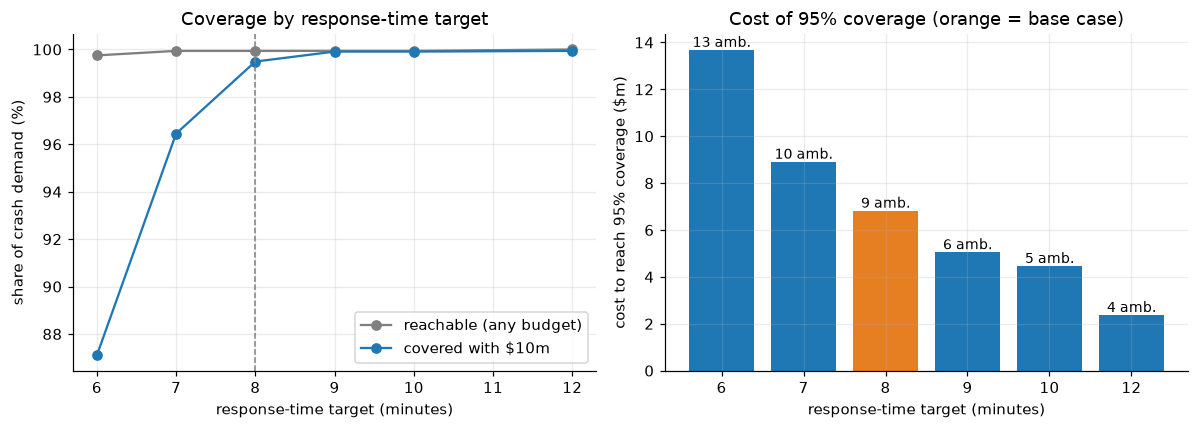

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(theta_df["theta_min"], theta_df["max_reach"] * 100, marker="o", color=GREY, label="reachable (any budget)")
ax[0].plot(theta_df["theta_min"], theta_df["cov_at_10m"] * 100, marker="o", color=BLUE, label="covered with $10m")
ax[0].axvline(8, color=GREY, ls="--", lw=1)
ax[0].set_xlabel("response-time target (minutes)"); ax[0].set_ylabel("share of crash demand (%)")
ax[0].set_title("Coverage by response-time target"); ax[0].legend(loc="lower right")

colors = [ORANGE if t == 8 else BLUE for t in theta_df["theta_min"]]
bars = ax[1].bar(theta_df["theta_min"].astype(str), theta_df["cost_for_95"], color=colors)
for b, n in zip(bars, theta_df["ambulances_for_95"]):
    ax[1].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{int(n)} amb.", ha="center", va="bottom", fontsize=9)
ax[1].set_xlabel("response-time target (minutes)"); ax[1].set_ylabel("cost to reach 95% coverage ($m)")
ax[1].set_title("Cost of 95% coverage (orange = base case)")

plt.tight_layout(); save(fig, "sens_response_time"); plt.show()

- A stricter response-time target barely changes how much demand can be reached at all. Reachable demand is the same at 7 minutes as at 8 (99.9%), and it only dips to 99.8% at 6 minutes.
- The real effect shows up when the budget is limited. With $10m, coverage drops from 99.5% at the 8-minute target to 96.5% at 7 minutes and 87% at 6 minutes.
- The bar chart on the right shows how much it costs to reach 95% coverage. Tightening the target from 8 to 6 minutes doubles the cost, from $6.8m to $13.7m. That is still well under the $30m budget.
- Going the other way, a looser target makes the plan much cheaper. At 10 minutes, 95% coverage needs only $4.5m (5 ambulances), and at 12 minutes only $2.4m (4 ambulances).

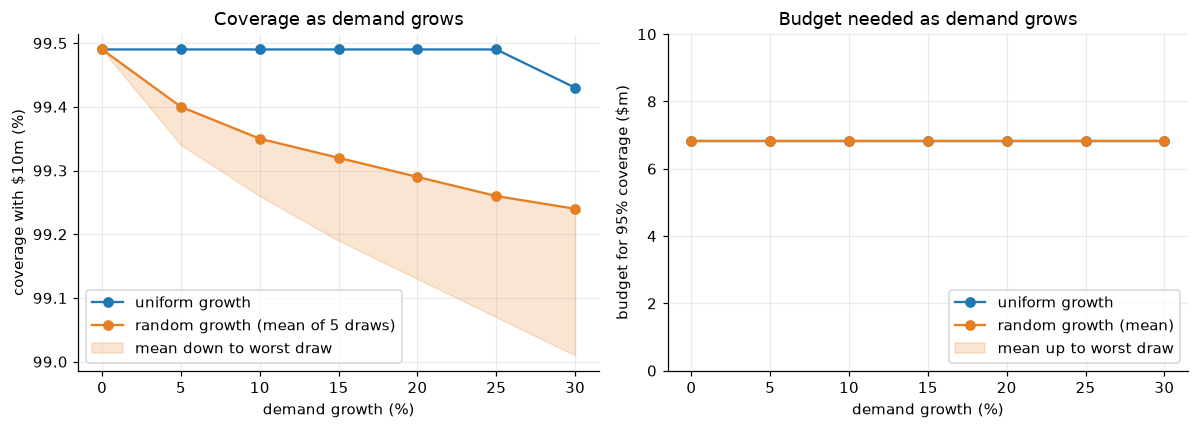

In [26]:
g = growth_df["growth"] * 100
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(g, growth_df["uniform_cov_10m"] * 100, marker="o", color=BLUE, label="uniform growth")
ax[0].plot(g, growth_df["random_cov_10m_mean"] * 100, marker="o", color=ORANGE, label="random growth (mean of 5 draws)")
ax[0].fill_between(g, growth_df["random_cov_10m_min"] * 100, growth_df["random_cov_10m_mean"] * 100,
                   color=ORANGE, alpha=0.2, label="mean down to worst draw")
ax[0].set_xlabel("demand growth (%)"); ax[0].set_ylabel("coverage with $10m (%)")
ax[0].set_title("Coverage as demand grows"); ax[0].legend(loc="lower left")

ax[1].plot(g, growth_df["uniform_budget_95"], marker="o", color=BLUE, label="uniform growth")
ax[1].plot(g, growth_df["random_budget_95_mean"], marker="o", color=ORANGE, label="random growth (mean)")
ax[1].fill_between(g, growth_df["random_budget_95_mean"], growth_df["random_budget_95_max"],
                   color=ORANGE, alpha=0.2, label="mean up to worst draw")
ax[1].set_ylim(0, max(10, growth_df["random_budget_95_max"].max() * 1.3))
ax[1].set_xlabel("demand growth (%)"); ax[1].set_ylabel("budget for 95% coverage ($m)")
ax[1].set_title("Budget needed as demand grows"); ax[1].legend(loc="lower right")

plt.tight_layout(); save(fig, "sens_demand_growth"); plt.show()

- Our model is built on historical crash data, so we tested how well the solution holds up if demand grows. We raised crash demand from 0% to 30% in steps of 5%, in two ways. In the first, every one of the 237 zones grows by the same percentage. In the second, the extra demand is spread across the zones at random, so some zones grow a lot and others barely at all. For each growth level we made 5 random draws, and we report the mean of the 5 and the worst draw, looking at coverage with a $10 million budget.
- In the left graph, uniform growth barely moves coverage. It stays at 99.5% all the way up to 25% growth and only slips to just above 99.4% at 30%. The budget needed to reach 95% coverage also does not change, at $6.83m at every growth level.
- Random growth hurts a little more. On average across the 5 draws, coverage falls from 99.5% with no growth to just above 99.2% at 30% growth. In the worst draw it falls to just above 99.0%. Even so, in every case we tested, coverage with $10 million stays above 99%. We read this as a sign that the solution is robust to much higher demand.
- Random growth costs more than uniform growth because the extra crashes can land in zones that are harder to reach in time, while uniform growth keeps demand in the same places as before.

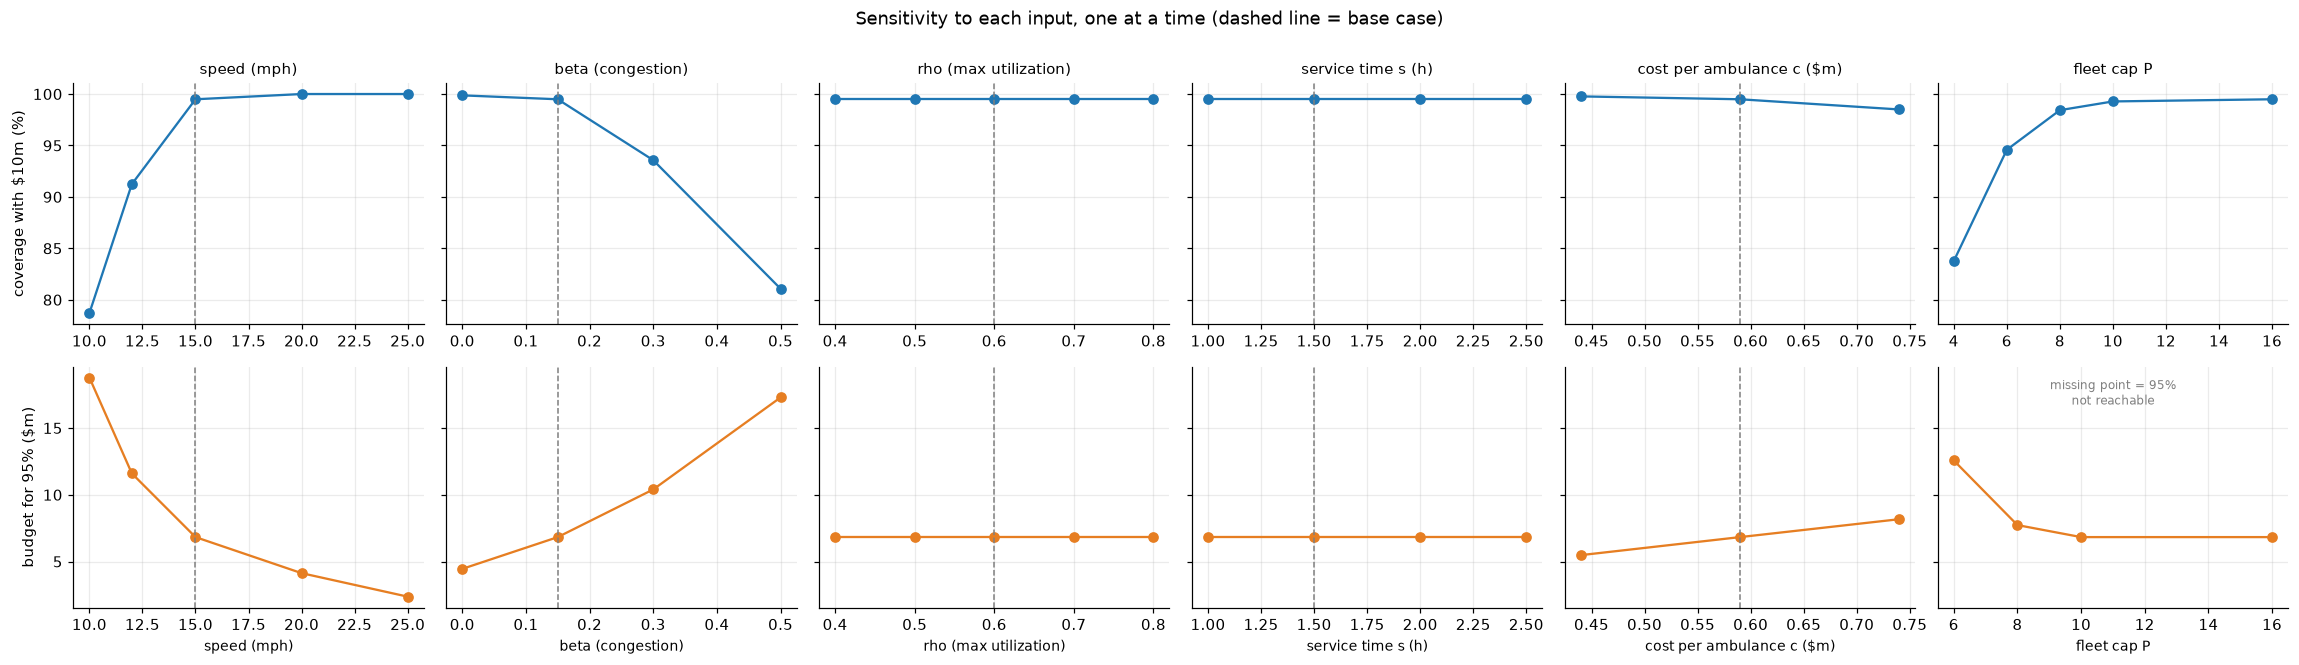

In [27]:
params = [("speed (mph)", 15), ("beta (congestion)", 0.15), ("rho (max utilization)", 0.60),
          ("service time s (h)", 1.5), ("cost per ambulance c ($m)", 0.59), ("fleet cap P", None)]

fig, axes = plt.subplots(2, 6, figsize=(21, 6), sharey="row")
for k, (name, base) in enumerate(params):
    sub = sens_df[sens_df["param"] == name].sort_values("value")
    axes[0, k].plot(sub["value"], sub["cov_at_10m"] * 100, marker="o", color=BLUE)
    axes[1, k].plot(sub["value"], sub["budget_for_95"], marker="o", color=ORANGE)
    axes[0, k].set_title(name, fontsize=10)
    axes[1, k].set_xlabel(name, fontsize=9)
    if base is not None:
        for r in (0, 1):
            axes[r, k].axvline(base, color=GREY, ls="--", lw=1)
    if sub["budget_for_95"].isna().any():
        axes[1, k].text(0.5, 0.95, "missing point = 95%\nnot reachable", transform=axes[1, k].transAxes,
                        ha="center", va="top", fontsize=8, color=GREY)

axes[0, 0].set_ylabel("coverage with $10m (%)")
axes[1, 0].set_ylabel("budget for 95% ($m)")
fig.suptitle("Sensitivity to each input, one at a time (dashed line = base case)", y=1.0)
plt.tight_layout(); save(fig, "sens_one_at_a_time"); plt.show()

- Here we test how sensitive the solution is to the main assumptions in the model. We change one parameter at a time and look at two outcomes: coverage with a $10 million budget, and the budget needed to reach 95% coverage.
- Ambulance speed matters a lot, and slower speeds hurt much more than faster ones help. At 20 mph, coverage with $10 million rises to essentially 100% and the budget for 95% falls to just above $4 million. But at 12 mph coverage drops to 91.2% and the budget for 95% nearly doubles to $11.6 million, and at 10 mph coverage falls to 78.7% and we would need $18.8 million, almost three times the base case of $6.83 million.
- Congestion (beta) has a similar effect. With no congestion, coverage is 99.9% and 95% costs $4.45 million. At the base value of 0.15 it is 99.5% and $6.83 million. Raising beta to 0.30 drops coverage to 93.6% and raises the budget for 95% to $10.4 million, and at 0.50 coverage falls to 81.1% and the budget rises to $17.3 million.
- Rho, the maximum utilization (0.6 in the base model), makes no difference. Coverage stays at 99.5% and the budget for 95% stays at $6.83 million for every value from 0.4 to 0.8. This is because in the final solution the ambulances are busy only a small share of the time, well below even 0.4, so the limit never binds.
- Service time per dispatch (the call, the service and the return to the station) behaves the same way. Between 1 and 2.5 hours, neither coverage nor the budget changes. So even if each call took about 70% longer than our 1.5 hour assumption, we would get the same solution, which points to its robustness.
- Cost per ambulance has a moderate effect. If the cost rises from $0.59 million to $0.74 million, coverage with $10 million falls from 99.5% to 98.5%, and the budget for 95% rises from $6.83 million to $8.17 million. At $0.44 million coverage rises to 99.8% and the budget for 95% falls to $5.48 million.
- Finally, fleet cap P. With 10 ambulances or more the results are essentially the base case (99.3% coverage with $10 million at P = 10 and $6.83 million for 95%). At 8 ambulances, coverage falls to 98.4% and 95% needs $7.73 million. At 6 ambulances coverage is 94.6% and 95% needs $12.6 million, and with only 4 ambulances coverage drops to 83.8% and 95% cannot be reached at any budget.


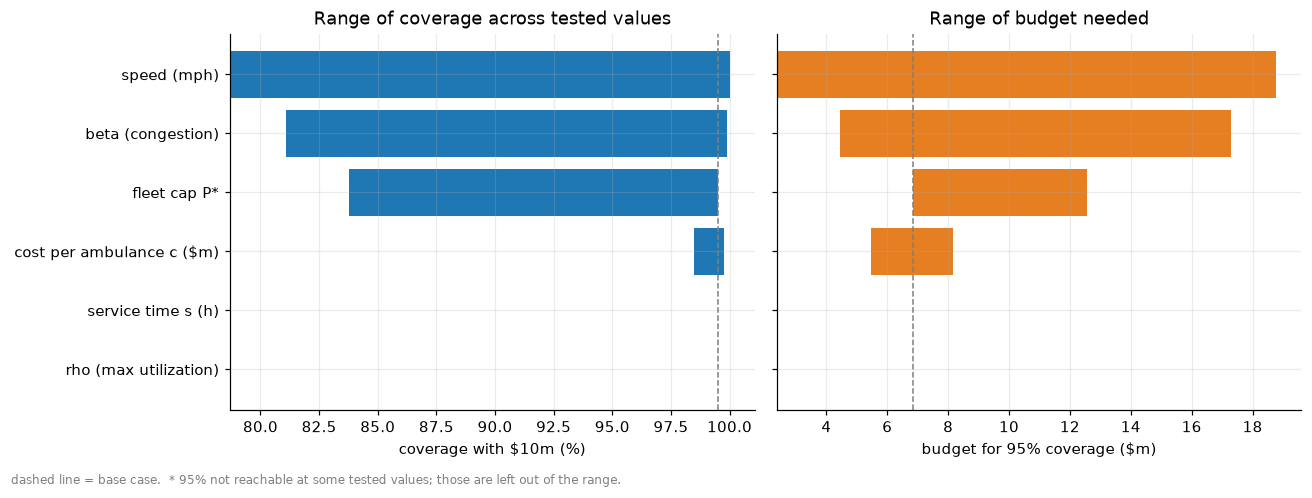

In [28]:
base_row = sens_df[(sens_df["param"] == "speed (mph)") & (sens_df["value"] == 15)].iloc[0]
base_cov, base_bud = base_row["cov_at_10m"] * 100, base_row["budget_for_95"]

rows = []
for name, _ in params:
    sub = sens_df[sens_df["param"] == name]
    star = "*" if sub["budget_for_95"].isna().any() else ""
    rows.append((name + star, sub["cov_at_10m"].min() * 100, sub["cov_at_10m"].max() * 100,
                 sub["budget_for_95"].min(), sub["budget_for_95"].max()))
tor = pd.DataFrame(rows, columns=["param", "cov_lo", "cov_hi", "bud_lo", "bud_hi"])
tor = tor.assign(swing=tor["cov_hi"] - tor["cov_lo"]).sort_values("swing")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
ax[0].barh(tor["param"], tor["cov_hi"] - tor["cov_lo"], left=tor["cov_lo"], color=BLUE)
ax[0].axvline(base_cov, color=GREY, ls="--", lw=1)
ax[0].set_xlabel("coverage with $10m (%)"); ax[0].set_title("Range of coverage across tested values")

ax[1].barh(tor["param"], tor["bud_hi"] - tor["bud_lo"], left=tor["bud_lo"], color=ORANGE)
ax[1].axvline(base_bud, color=GREY, ls="--", lw=1)
ax[1].set_xlabel("budget for 95% coverage ($m)"); ax[1].set_title("Range of budget needed")

fig.text(0.01, 0.01, "dashed line = base case.  * 95% not reachable at some tested values; those are left out of the range.",
         fontsize=8, color=GREY)
plt.tight_layout(rect=(0, 0.03, 1, 1)); save(fig, "sens_ranking"); plt.show()

- Based on the charts above, we made this chart to compare which of the assumed parameters moves the results the most. The bars show the range of each outcome across all the values we tested, for coverage with $10 million (left) and for the budget needed to reach 95% coverage (right).
- For coverage with $10 million, the three parameters with the widest range are speed (78.7% to 100%), beta, the congestion factor (81.1% to 99.9%), and the fleet cap (83.8% to 99.5%). Cost per ambulance has a small effect (98.5% to 99.8%), while rho and service time have none.
- For the budget needed to reach 95% coverage, the largest ranges again come from speed ($2.4 million to $18.8 million), beta ($4.5 million to $17.3 million) and the fleet cap. The fleet cap bar understates its effect, because with only 4 ambulances 95% coverage cannot be reached at any budget, so that point is left out of the chart.
- The takeaway is that the solution is most sensitive to how fast ambulances can actually travel, which is what speed and congestion both describe, and to how many ambulances we can have. It is not sensitive to the utilization limit or to how long each call takes.


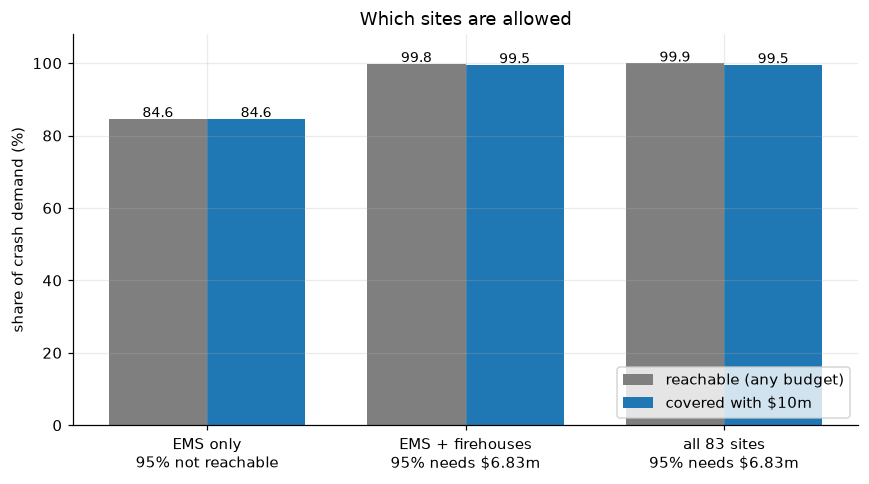

In [29]:
x = np.arange(len(sites_df)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
b1 = ax.bar(x - w / 2, sites_df["max_reach"] * 100, w, color=GREY, label="reachable (any budget)")
b2 = ax.bar(x + w / 2, sites_df["cov_at_10m"] * 100, w, color=BLUE, label="covered with $10m")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5, f"{b.get_height():.1f}", ha="center", fontsize=9)

labels = [f"{s}\n" + ("95% not reachable" if pd.isna(b) else f"95% needs ${b:.2f}m")
          for s, b in zip(sites_df["sites"], sites_df["budget_for_95"])]
ax.set_xticks(x, labels)
ax.set_ylim(0, 108); ax.set_ylabel("share of crash demand (%)")
ax.set_title("Which sites are allowed"); ax.legend(loc="lower right")
plt.tight_layout(); save(fig, "sens_site_sets"); plt.show()

- In our original solution, we assume that all 83 candidate sites can be used: 14 EMS stations, 47 firehouses and 22 hospitals. Here we test what happens to maximum coverage, coverage with $10 million and the budget needed for 95% coverage if some of those sites are not available.
- In the base case, with all 83 sites, 99.9% of crash demand is within reach of at least one site, coverage with $10 million is 99.5% and reaching 95% coverage costs $6.83 million.
- If we remove the 22 hospitals and keep the 14 EMS stations and 47 firehouses, almost nothing changes. Reachable demand dips slightly from 99.94% to 99.79%, while coverage with $10 million (99.5%) and the budget for 95% coverage ($6.83 million) are exactly the same. In other words, hospitals add very little to the solution.
- If we keep only the 14 existing EMS stations, the solution gets much worse. Only 84.6% of crash demand can be reached from those stations, so coverage with $10 million is also 84.6%, and spending more would not help. 95% coverage is not possible at any budget.
- Overall, converting firehouses is what makes the solution work, and hospitals are not needed. This matches our smaller plan for 99% coverage, which uses 8 EMS stations and 2 firehouses and no hospitals.